# Lab 5: Rate vs Time
In this lab, you will use the recording from the SpikerBox, and analyze the spike rates over time, taking the audio trace, extracting the spike times, and plotting firing rate as function of time.

**Important**: Upload your .wav file spike recording to the same folder in google drive as this file.

*If you don't have a .wav file,* you can [download this one (crickets2.wav)](https://reed.cs.depaul.edu/peterh/courses/neu256/weeks/wk5/crickets2.wav) into your google drive.

**Goal:** The goal of this lab is to determine the number of spikes per second from a spikerbox recording of a cricket, then reflect about how this can be used.

**Instructions:** In the cells below, there are a lot of cells with placekeepers like "WHAT". Your challenge is to determine what should be there. You might want to take a look at the current visuals for each cell (where there are some), to see what to expect.

There are also some hidden cells below some of the cells in "Spoilers" sections. If you're stuck, you can check those out for help, or ask Mr Peabody.

In [ ]:
# Some imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import read  # Lets you read .wav file
from IPython.display import Audio  # Lets you play the file

%matplotlib inline

In [ ]:
# Mount your drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Section 1: Read in the data and plot it

In [ ]:
# read in the audio trace from the wav file you collected with the spikerbox

# Enter the name of your file below
# Note: You can click the dots to the right of the filename in the sidebar
# and "Copy path" and insert it.
audiofile = '/content/drive/YOUR FILE NAME'

srate, audio = read(audiofile)
print(f'sampling rate: {srate} per second')

# You might have gotten a 2-channel (left and right) recording.
# Check it, and if so, drop the second channel
np.shape(audio)

In [ ]:
# If it was 2-dimensional (e.g., (X,2) instead of (X,)), drop one channel
# audio = audio[:,0]

In [ ]:
# a handy utility function to convert time in seconds to
# the relevant index of the time and spikes arrays
def time_index(t):
    return int(t*srate)

In [ ]:
# create a 'time' array, for which time(ii) corresponds to audio(ii)
# (hint: you will need to use the length of the audio array and the sample
# rate). (The units for time will be seconds.)
total_time = WHAT
time = np.arange(0, WHAT, 1/srate)

Text(0, 0.5, 'Volts (arbitrary units)')

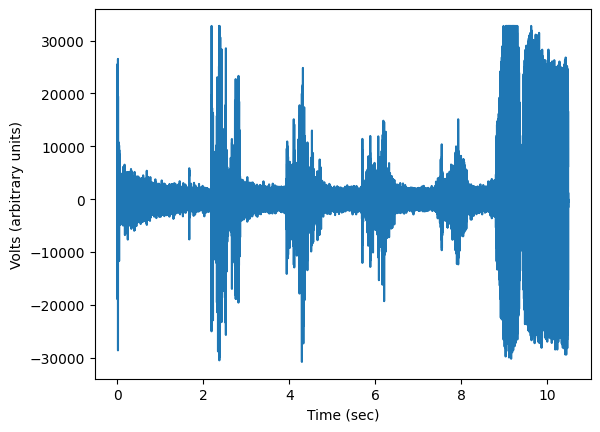

In [ ]:
# plot the audio as a function of time in seconds
plt.plot(time,audio)

plt.xlabel('Time (sec)')
# with the SpikerBox, we don't know the exact scale of the audio (this doesn't
# matter, because we're only interested in the spikes, which are clearly distinguishable)
plt.ylabel('audio (arbitrary units)')

In [ ]:
# play the audio
Audio(audio, rate=srate)

## Optional: Zoom in to see a more fine-grained view

Text(0, 0.5, 'audio (arbitrary units)')

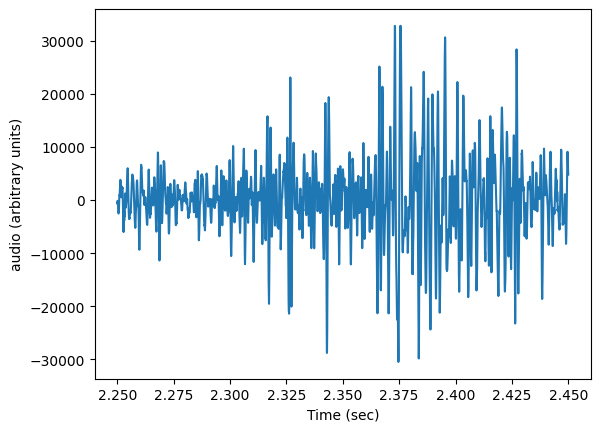

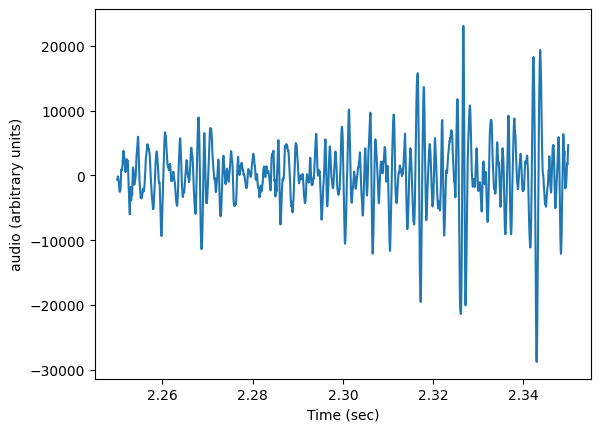

In [ ]:
# For visualization, you can zoom in, to view a little bit of the file

zoom_start = # you choose the time
zoom_end = # you choose the time

plt.figure()
# use the time_index function to put in start and end indices
plt.plot(time[FROM_WHAT:TO_WHAT],
         audio[FROM_WHAT:TO_WHAT])
plt.xlabel('Time (sec)')
plt.ylabel('audio (arbitrary units)')

# wanna see another? Use a zoom_end very close to zoom_start
plt.figure()
# use the time_index function to put in start and end indices
plt.plot(time[FROM_WHAT:TO_WHAT],
         audio[FROM_WHAT:TO_WHAT])
plt.xlabel('Time (sec)')
plt.ylabel('audio (arbitrary units)')

##Post processing
Was there a bunch of noise in your recording like in this one -- before .1 seconds and after about 8.5 seconds?

If so, you can trim off the ends of the arrays.

Text(0, 0.5, 'audio (arbitrary units)')

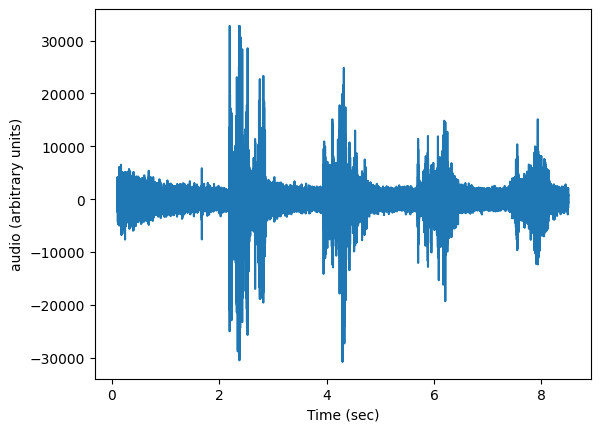

In [ ]:
# trim both files if you want. Otherwise, comment these out.
start_ind = WHAT
end_ind = WHAT
audio = audio[start_ind:end_ind]
time = time[start_ind:end_ind]

# See what it looks like now
plt.figure()
plt.plot(time,audio)
plt.xlabel('Time (sec)')
plt.ylabel('audio (arbitrary units)')

# Section 2:
Process the waveform so that you have a signal of just 1's and 0's: 1's for spikes and 0's for everything else


Text(0.5, 0, 'Time (sec)')

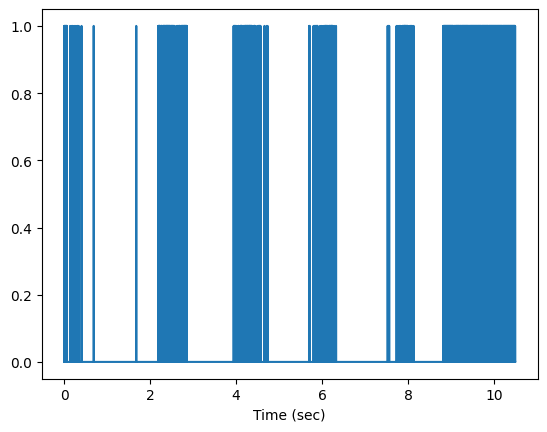

In [ ]:
# the threshold should be set by eyeing the data and determining what value will
# separate spike events from noise this is somewhat arbitrary
# Enter what you think the threshold should be for your data.
threshold = YOUR THRESHOLD

# copy the data in 'audio' into a new vector called 'spikes'
spikes = audio

# set every entry in 'spikes' which is less than 'threshold' equal to 0.
# Hint: there's a tricky little way to index this with a condition, essentially
# selecting all the items of the array that satisfy the condition.
spikes[WHAT]=0

# In order to convert each spike into a SINGLE 1 (rather than multiple 1's),
# take the discrete difference of 'spikes'.
# Use np.diff subtracts each element from the subsequent element, so you'll
# get positive numbers where it's going up, and negative where it's going down.
spikes = WHAT

# diff returns a vector one shorter than the input because it subtracts each
# element from the previous one.

# Add one extra entry to 'spikes,' so that it has the same number of elements as
# 'time'
spikes = np.append(spikes,[0])

# set every entry in 'spikes' that is less than 'threshold' equal to 0s
spikes[CONDITION] = 0

# set every entry in 'spikes' that is greater than or equal to 'threshold' equal to 1
spikes[CONDITION] = 1

plt.figure()
plt.plot(time,spikes)
plt.xlabel('Time (sec)')

# Should look something like this:

### Spoilers

Text(0.5, 0, 'Time (sec)')

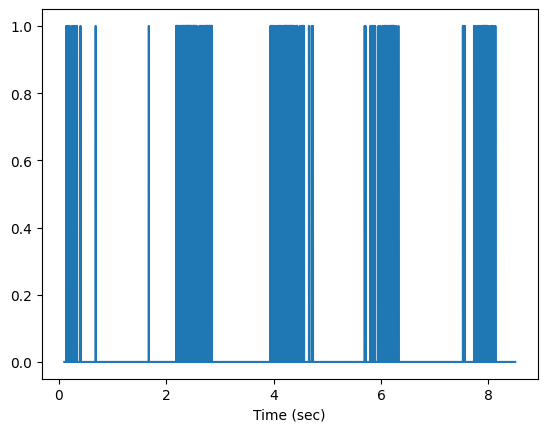

In [ ]:
'''
# Set the threshold by eyeing the data and determining what value will
# separate spike events from noise. (This is somewhat arbitrary.)
# Enter what you think the threshold should be for your data.
threshold = 5000

# copy the data in 'audio' into a new vector called 'spikes'
spikes=audio

# set every entry in 'spikes' which is less than 'threshold' equal to 0
spikes[spikes<threshold]=0

# In order to convert each spike into a SINGLE 1 (rather than multiple 1's),
# take the discrete difference of 'spikes'.
# Use np.diff subtracts each element from the subsequent element, so you'll
# get positive numbers where it's going up, and negative where it's going down.
spikes=np.diff(spikes)

# diff returns a vector one shorter than the input because it subtracts each
# element from the previous one, so add one extra entry to 'spikes,' so that
# it has the same number of elements as 'time'
spikes=np.append(spikes,[0])

# *Again* set every entry in 'spikes' that is less than 'threshold' equal to 0
# because we're looking for the upward jumps.
spikes[ spikes < threshold ] = 0

# Set every entry in 'spikes' that is greater than or equal to 'threshold' = 1
spikes[spikes>=threshold] = 1

plt.figure()
plt.plot(time,spikes)
plt.xlabel('Time (sec)')
'''

# Section 3: Create plot of firing rate versus time


Now you're ready to count the number of spikes per second. Use a while loop to "drag" a "window" of a given time width across the recording, counting the number of spikes in the window at each step.

Text(0.5, 1.0, 't_window = 1.0 s, t_slide = 0.1 s')

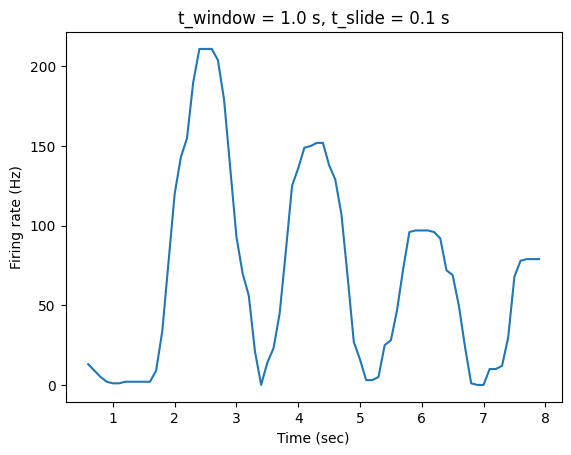

In [ ]:
# Parameters for the sliding window

# create one parameter for the width of the window in seconds (hint: 1 is good)
t_window = WHAT
# create another parameter for the time step for each sliding step (about a tenth)
t_slide = WHAT

# Create two related parameters for the number of data points per window and number
# of data points per sliding step. (I.e., convert the above two parameters
# from time into number of data points, by multiplying the time by the
# sampling rate.) Round it off to get an integer.
wind_dat_pts = WHAT
slide_dat_pts = WHAT

# A parameter for the total number of data points left in spikes
total_dat_pts = WHAT

# Create vectors full of 0's to hold the firing rate values and
# their associated times. The length of both should be (an integer representing)
# the total number of data points minus the number of points in the window, all
# divided by the number of data points per slide.
# Hints: use the built-in int function and an np function to make the vectors

# A variable for the number of points in both vectors.
firing_rate_points = int((total_dat_pts - wind_dat_pts) / slide_dat_pts)
# the two vectors
firing_rate = WHAT
plot_time = WHAT

# Now set up the initial parameters for the loop with a start from 0 and
# stop equal to the number of data points in a window.
# Both of these will be incremented at the end of each iteration of the loop.
start = 0
stop = WHAT

# index for storing the firing_rate and plot_time, starting at 0
i_p = 0

# Start the loop, going while the stop value is less than the total number of
# data points.
#
while(stop < WHAT):
  # Into the next index of the firing rate vector, store:
  # for the current window, the sum of the number of spikes (which are all
  # set to 1) divided by the width of the window in seconds.
  firing_rate[i_p] = WHAT
  # Into the next index of the times vector for the plot, store the average
  # time (from the time vector) between the start and stop for the current position.
  plot_time[i_p] = WHAT

  # increment the index
  i_p = i_p+1
  # increment both start and stop by the number of points per slide
  start = WHAT
  stop = WHAT


# Create a plot of firing rate versus time
plt.figure()
plt.plot(plot_time, firing_rate)
plt.xlabel('Time (sec)')
plt.ylabel('Firing rate (Hz)')
plt.title(f't_window = {t_window:3.1f} s, t_slide = {t_slide:3.1f} s')


### Spoilers

Text(0.5, 1.0, 't_window = 1.0 s, t_slide = 0.1 s')

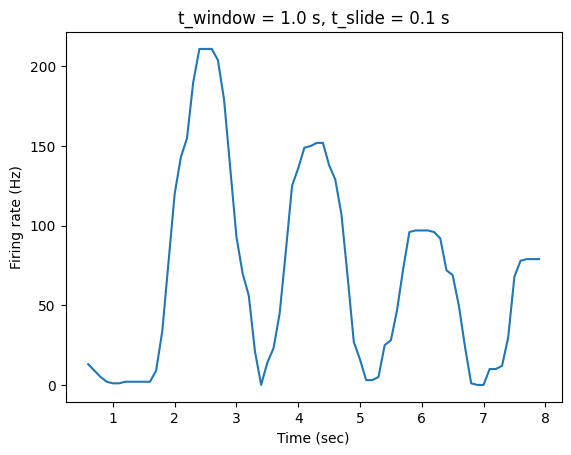

In [ ]:
'''
# Parameters for the sliding window

# create one parameter for the width of the window in seconds
t_window = 1.0
# create another parameter for the time step for each sliding step
t_slide = 0.1

# Create two related parameters for the number of data points per window and number
# of data points per sliding step. (I.e., convert the above two parameters
# from time into number of data points, by multiplying the time by the
# sampling rate.)
wind_dat_pts = round(t_window*srate)
slide_dat_pts = round(t_slide*srate)

# A parameter for the total number of data points
total_dat_pts = np.size(spikes)

# For efficiency, you can pre-allocate vectors to hold the firing rate values and
# their associated times. The length of both should be the
# total number of data points minus the number of points in the window, all
# divided by the data points per slide.
# Hints: use the built-in int function and an np function to make the vectors

# A variable for the number of points in both vectors.
firing_rate_points = int((total_dat_pts - wind_dat_pts) / slide_dat_pts)

# the two vectors
firing_rate = np.zeros(firing_rate_points)
plot_time = np.zeros(firing_rate_points)

# Now set up the initial parameters for the loop with a start from 0 and
# stop equal to the number of data points in a window.
# Both of these will be incremented at the end of each iteration of the loop.
start = 0
stop = wind_dat_pts

# index for storing the firing_rate and plot_time
i_p = 0

# Start the loop, going while the stop value is less than the total number of
# data points

while(stop < total_dat_pts):
  # Into the next index of the firing rate vector, store:
  # for the current window, the sum of the number of spikes (which are all
  # set to 1) divided by the width of the window in seconds.
  firing_rate[i_p] = np.sum(spikes[start:stop]) / t_window
  # Into the next index of the times vector for the plot, store the average
  # time (from the time vector) between the start and stop for the current position.
  plot_time[i_p] = (time[start]+time[stop]) / 2

  # increment the index
  i_p = i_p+1
  # increment both start and stop by the number of points per slide
  start = start+slide_dat_pts
  stop = stop+slide_dat_pts


# Create a plot of firing rate versus time
plt.figure()
plt.plot(plot_time,firing_rate)
plt.xlabel('Time (sec)')
plt.ylabel('Firing rate (Hz)')
plt.title(f't_window = {t_window:3.1f} s, t_slide = {t_slide:3.1f} s')
'''

# Part 4: Calculate mean spikes per second overall



There's a super easy way to do this. Ideas?

Ok, here are some hints
* What's an easy way to calculate the number of spikes?
* What's an easy way to calculate the total amount of time in your (trimmed) sample?

In [ ]:
# You can do the calculation in one line, or separately calculate
# the total number of spikes and the total time.
spikes_per_second = WHAT
print(f'Overall spikes per second: {spikes_per_second:.2f}')

### Spoilers

In [ ]:
# Maybe:
np.sum(spikes)

np.int64(554)

In [ ]:
# and
total_time = np.size(audio)/srate
total_time

8.4

In [ ]:
spikes_per_second = np.sum(spikes)/total_time
print(f'Overall spikes per second: {spikes_per_second:.2f}')

Overall spikes per second: 65.95


# Part 5: What else can you do with this?

How would it help you analyze the data you collected from your cricket?

*Enter your reflections here*
